 # MASTER THESIS ON WIND ENERGY TO HYDROGEN IN JUPYTER NOTEBOOKS, PYTHON

- #### By Agyemang-Boakye Bright
- #### MSc Renewable Energy Management at TH kÖLN


#### Purpose of this script is to read hourly wind data in MW which is the wind-power profile for SIEMENS SWT-2.3-113 2300 12%, computes annual energy, estimate hydrogen production for two electrolyser technologies which are Alkaline and PEM using Low Heating Value (LHV) basis, sizes electrolysers to a chosen power metric, estimate storage and transport needs, computes CAPEX and logistics costs in EUR, and produces a plots and a summary. 

 - #### Keta, Ghana analysis (PEM & Alkaline sizing, storage, LCOH) 
 - #### Storage-module calculations (number of modules for several vendor module sizes)
 - #### Visuals (matplotlib PNGs)
 - #### Outputs

-----------------------------------------------------------------------------------------------------------

### 1. Header and Imports

In [1]:
import numpy as np
import pandas as pd

- The numpy library was for numerical arrays and fast matrix math,
- pandas was used for building and saving summary and importing the time series data.

------------------------------------------------------------------------------------------------------------------------------------------

### 2. General Parameters

In [2]:
# ==============================
# 1. GENERAL PARAMETERS
# ==============================
HOURS_PER_YEAR = 8760
LIFETIME_YRS = 20
DISCOUNT_RATE = 0.08

ELY_SIZE_MW = 3.5
MAX_GRID_SHARE = 0.20
COMPRESSION_KWH_KG = 3.0
TRANSPORT_COST_EUR_KG = 1.5
STORAGE_CAPEX_EUR_KG = 600

WIND_LCOE_EUR_MWH = 57.74
GRID_PRICE_EUR_MWH = 145       
EXPORT_PRICE_EUR_MWH = 50

- These are the general parameters used that are used in the calculations with the electrolyser capacity of 4.5MW and the feed in tarrif for wind energy in Ghana and the current grid electricty cost.

--------------------------------------------------------------------

### 3. Systems Availability and Data.

In [3]:
# ==============================
# 2. AVAILABILITY (MAINTENANCE)
# ==============================
ELY_AVAIL = {"ALK": 0.96, "PEM": 0.98}
GRID_AVAIL = 0.98

# ==============================
# 3. TECHNOLOGY DATA
# ==============================
TECHS = {
    "ALK": {
        "capex_eur_kw": 2301,
        "opex_eur_kwyr": 43,
        "sec_kwh_kg": 51.0,
        "min_load_frac": 0.15,
        "storage_kg": 1800
    },
    "PEM": {
        "capex_eur_kw": 2305,
        "opex_eur_kwyr": 64,
        "sec_kwh_kg": 47.5,
        "min_load_frac": 0.05,
        "storage_kg": 1800
    }
}

- This section describes the availability of the grid and electrolyser due to curtailement and or maintainance
- The electrolyser parameters are also set here in TECHS.

-------------------------------------------------------------------------------

### 4. Time Series Data and Annuity Factor 

In [4]:
# ==============================
# 4. WIND TIME SERIES
# ==============================
df_wind = pd.read_csv("OLD Untitled Folder/wind_data1.csv")
df_wind.index = pd.date_range("2026-01-01", periods=8760, freq="h")

# ==============================
# 5. ANNUITY FACTOR
# ==============================
def annuity_factor(r, n):
    return (r * (1 + r)**n) / ((1 + r)**n - 1)

AF = annuity_factor(DISCOUNT_RATE, LIFETIME_YRS)


- pandas was used to import the Nordex data to aid in the analysis.
- The annuity factor was used to calculate the annual payment of the project lifetime usingthe discount rate.

------------------------------------------------------------------

### 5. The Main Model

-The main module is a sumulation of the system below

- np.random.seed(42) sets the random number generator to a fixed starting point and ensures that any randomly generated maintenance events (e.g., outages, failures, downtime patterns) are identical every time the model is runned.
- P_NOM is the electrolyser size
- P_Min is the minimum load fraction of the electrolysers
- Wind_p is the a power (MW) in the CSV file of the time series data
- ely_power_raw is what the wind could give the electrolyser and ely_power _eff is what the electrolyser actually consumes
- Similary grid import_raw is what the grid could give the electrolyser and grid_import _eff is what the electrolyser actually consumes
- surplus_export is the wind power that exceeds the electrolyser capacity.
- The Levelized Cost of Hydrogen was calculated at in this model using the capex and opex with the Annuity Factor

In [5]:
# ==============================
# 6. MAIN SIMULATION FUNCTION
# ==============================
def run_model(tech, p):

    np.random.seed(42)  # reproducible maintenance

    df = df_wind.copy()

    P_NOM = ELY_SIZE_MW
    P_MIN = P_NOM * p["min_load_frac"]

    # --- ELECTROLYSER AVAILABILITY (TIME-BASED) ---
    ely_available = np.random.rand(len(df)) < ELY_AVAIL[tech]

    # --- ELECTROLYSER POWER FROM WIND ---
    df["ely_power_raw"] = np.minimum(df["wind_p"], P_NOM)
    df.loc[df["ely_power_raw"] < P_MIN, "ely_power_raw"] = 0.0
    df.loc[~ely_available, "ely_power_raw"] = 0.0

    df["ely_power_eff"] = df["ely_power_raw"]

    # --- GRID IMPORT ---
    df["grid_import_raw"] = (P_NOM - df["ely_power_raw"]).clip(lower=0)
    df["grid_import_raw"] = np.minimum(
        df["grid_import_raw"], MAX_GRID_SHARE * P_NOM
    )

    df["grid_import_eff"] = df["grid_import_raw"] * GRID_AVAIL
    df.loc[~ely_available, "grid_import_eff"] = 0.0

    # --- SURPLUS EXPORT ---
    df["surplus_export"] = (df["wind_p"] - P_NOM).clip(lower=0)

    # ==============================
    # ENERGY BALANCE
    # ==============================
    ely_energy_mwh = df["ely_power_eff"].sum()
    grid_energy_mwh = df["grid_import_eff"].sum()
    total_energy_mwh = ely_energy_mwh + grid_energy_mwh

    # ==============================
    # HYDROGEN PRODUCTION
    # ==============================
    df["H2_kg"] = (
        (df["ely_power_eff"] + df["grid_import_eff"]) * 1000
    ) / p["sec_kwh_kg"]

    annual_h2_kg = df["H2_kg"].sum()

    # ==============================
    # OPERATING HOURS
    # ==============================
    operating_hours = (df["ely_power_eff"] > 0).sum()
    downtime_hours = HOURS_PER_YEAR - operating_hours

    # ==============================
    # CAPACITY FACTOR
    # ==============================
    flh = ely_energy_mwh / P_NOM
    cf = flh / HOURS_PER_YEAR

    # ==============================
    # MONTHLY AGGREGATION
    # ==============================
    monthly = df.resample("ME").agg({
        "ely_power_eff": "sum",
        "grid_import_eff": "sum",
        "surplus_export": "sum",
        "H2_kg": "sum"
    })

    # ==============================
    # COSTS
    # ==============================
    capex_ely = p["capex_eur_kw"] * P_NOM * 1000
    capex_storage = p["storage_kg"] * STORAGE_CAPEX_EUR_KG
    annual_capex = (capex_ely + capex_storage) * AF

    opex_fixed = p["opex_eur_kwyr"] * P_NOM * 1000

    elec_cost = (
        ely_energy_mwh * WIND_LCOE_EUR_MWH +
        grid_energy_mwh * GRID_PRICE_EUR_MWH
    )

    compression_cost = annual_h2_kg * COMPRESSION_KWH_KG * GRID_PRICE_EUR_MWH / 1000
    transport_cost = annual_h2_kg * TRANSPORT_COST_EUR_KG
    export_revenue = df["surplus_export"].sum() * EXPORT_PRICE_EUR_MWH

    annual_cost = (
        annual_capex + opex_fixed + elec_cost +
        compression_cost + transport_cost - export_revenue
    )

    lcoh = annual_cost / annual_h2_kg

    # ==============================
    # PRINT RESULTS
    # ==============================
    print(f"\n--- {tech} ELECTROLYSER ---")
    print(f"Annual H₂ production: {annual_h2_kg:,.0f} kg")
    print(f"Sum of monthly H₂:    {monthly['H2_kg'].sum():,.0f} kg")
    print(f"Operating hours:      {operating_hours} h/yr")
    print(f"Downtime hours:       {downtime_hours} h/yr")
    print(f"FLH:                 {flh:.0f} h")
    print(f"Capacity factor:     {cf:.1%}")
    print(f"LCOH:                {lcoh:.2f} €/kg")
    print("")

    print(f"Electrolyser rated power: {ELY_SIZE_MW:.1f} MW")
    renewable_share = ely_energy_mwh / total_energy_mwh
    print(f"Renewable electricity share: {renewable_share:.1%}")
    print(f"Grid electricity share: {1-renewable_share:.1%}")
    print("")
    print(f"Wind energy used by electrolyser: {ely_energy_mwh:,.0f} MWh")
    print(f"Grid electricity imported: {grid_energy_mwh:,.0f} MWh")
    print(f"Surplus wind exported: {df['surplus_export'].sum():,.0f} MWh")
    print("")
    print("")

    print(f"Annualized CAPEX: {annual_capex:,.0f} €/yr")
    print(f"Fixed OPEX: {opex_fixed:,.0f} €/yr")
    print(f"Electricity cost: {elec_cost:,.0f} €/yr")
    print(f"Compression cost: {compression_cost:,.0f} €/yr")
    print(f"Transport cost: {transport_cost:,.0f} €/yr")
    print(f"Surplus revenue: {export_revenue:,.0f} €/yr")
    print("")
    
    avg_daily_h2 = annual_h2_kg / 365
    print(f"Average daily H₂ production: {avg_daily_h2:,.0f} kg/day")
    print(f"Storage capacity: {p['storage_kg']:,.0f} kg")
    print(f"Days of storage coverage: {p['storage_kg']/avg_daily_h2:.1f} days")
    print("")

    operating_hours = (df['ely_power_eff'] > 0).sum()
    print(f"Electrolyser operating hours: {operating_hours} h/yr")
    print(f"Electrolyser downtime (incl. low wind + maintenance): {8760-operating_hours} h/yr")

    print(f"Minimum load fraction: { P_MIN }")
    print("")
    # return {
    #     "hourly": df,
    #     "monthly": monthly,
    #     "annual_h2_kg": annual_h2_kg
    #}
    return {
        "hourly": df,
        "monthly": monthly,
        "annual_h2_kg": annual_h2_kg,
        "costs": {
            "capex": annual_capex,
            "opex": opex_fixed,
            "electricity": elec_cost,
            "compression": compression_cost,
            "transport": transport_cost,
                "export": export_revenue,
            "total": annual_cost,
            "lcoh": lcoh
    }
}

# ==============================
# 7. RUN MODELS
# ==============================
results = {}
for tech, params in TECHS.items():
    results[tech] = run_model(tech, params)



--- ALK ELECTROLYSER ---
Annual H₂ production: 536,122 kg
Sum of monthly H₂:    536,122 kg
Operating hours:      8416 h/yr
Downtime hours:       344 h/yr
FLH:                 7163 h
Capacity factor:     81.8%
LCOH:                6.63 €/kg

Electrolyser rated power: 3.5 MW
Renewable electricity share: 91.7%
Grid electricity share: 8.3%

Wind energy used by electrolyser: 25,070 MWh
Grid electricity imported: 2,272 MWh
Surplus wind exported: 6,850 MWh


Annualized CAPEX: 930,267 €/yr
Fixed OPEX: 150,500 €/yr
Electricity cost: 1,777,006 €/yr
Compression cost: 233,213 €/yr
Transport cost: 804,183 €/yr
Surplus revenue: 342,475 €/yr

Average daily H₂ production: 1,469 kg/day
Storage capacity: 1,800 kg
Days of storage coverage: 1.2 days

Electrolyser operating hours: 8416 h/yr
Electrolyser downtime (incl. low wind + maintenance): 344 h/yr
Minimum load fraction: 0.525


--- PEM ELECTROLYSER ---
Annual H₂ production: 588,242 kg
Sum of monthly H₂:    588,242 kg
Operating hours:      8601 h/yr
D

In [6]:
import pandas as pd

# ==============================
# BUILD MONTHLY COMPARISON TABLE
# ==============================
comparison = pd.DataFrame({
    "ALK_H2_kg": results["ALK"]["monthly"]["H2_kg"],
    "PEM_H2_kg": results["PEM"]["monthly"]["H2_kg"],
    "ELY_energy_MWh": results["ALK"]["monthly"]["ely_power_eff"],
    "Grid_import_MWh": results["ALK"]["monthly"]["grid_import_eff"],
    "Surplus_export_MWh": results["ALK"]["monthly"]["surplus_export"]
})

# ==============================
# OPTIONAL: TOTALS ROW (RECOMMENDED)
# ==============================
comparison.loc["Total"] = comparison.sum()

comparison


,ALK_H2_kg,PEM_H2_kg,ELY_energy_MWh,Grid_import_MWh,Surplus_export_MWh
2026-01-31 00:00:00,43697.450980,48132.757895,1908.6,319.970,313.1
2026-02-28 00:00:00,43349.294118,47427.663158,2113.5,97.314,809.2
2026-03-31 00:00:00,48783.882353,53483.536842,2462.4,25.578,1094.3
2026-04-30 00:00:00,47068.823529,51858.442105,2307.9,92.610,477.0
2026-05-31 00:00:00,43481.450980,47673.094737,1906.6,310.954,151.9
2026-06-30 00:00:00,46303.960784,50792.378947,2199.9,161.602,303.0
2026-07-31 00:00:00,49411.764706,53936.842105,2520.0,0.000,1382.6
2026-08-31 00:00:00,48107.843137,53494.736842,2453.5,0.000,1531.4
2026-09-30 00:00:00,47205.019608,51861.852632,2322.0,85.456,663.0
2026-10-31 00:00:00,42357.843137,46130.442105,1800.1,360.150,83.7


--------------------------------------------------------------------------------

### 6. Monthly Hydrogen Production Comparison Table

### 7. Plots

- matplotlib.pyplot Loads the pyplot interface, which provides simple functions for creating plots.
- matplotlib as mpl imports the entire Matplotlib library under the alias mpl

In [7]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Sans", "Times"],
    "font.size": 15,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.0,
    "grid.linewidth": 0.6,
    "grid.alpha": 0.4,
    "figure.dpi": 95
})

------------

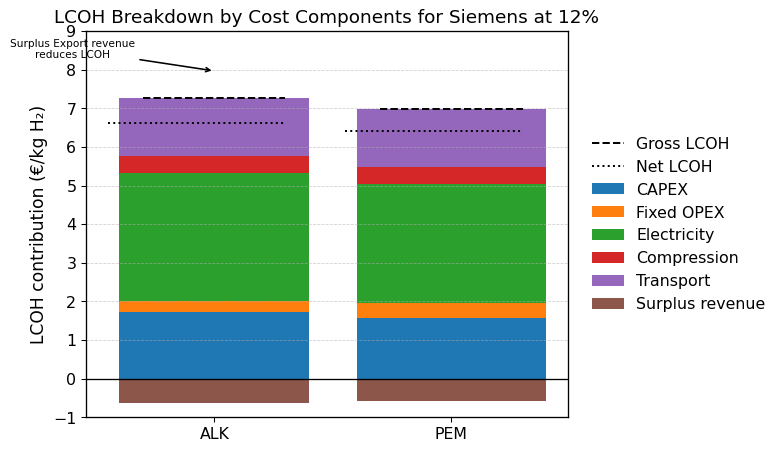

In [8]:
import numpy as np
import matplotlib.pyplot as plt

labels = ["ALK", "PEM"]
x = np.arange(len(labels))

def lcoh_component(results, tech, key):
    return results[tech]["costs"][key] / results[tech]["annual_h2_kg"]

capex       = np.array([lcoh_component(results, "ALK", "capex"),
                         lcoh_component(results, "PEM", "capex")])

opex        = np.array([lcoh_component(results, "ALK", "opex"),
                         lcoh_component(results, "PEM", "opex")])

electricity = np.array([lcoh_component(results, "ALK", "electricity"),
                         lcoh_component(results, "PEM", "electricity")])

compression = np.array([lcoh_component(results, "ALK", "compression"),
                         lcoh_component(results, "PEM", "compression")])

transport   = np.array([lcoh_component(results, "ALK", "transport"),
                         lcoh_component(results, "PEM", "transport")])

export      = np.array([-lcoh_component(results, "ALK", "export"),
                         -lcoh_component(results, "PEM", "export")])


gross_lcoh = capex + opex + electricity + compression + transport
net_lcoh   = gross_lcoh + export
fig, ax = plt.subplots(figsize=(8.5, 5))
fig.subplots_adjust(right=0.78)

bottom = np.zeros(len(x), dtype=float)


ax.bar(x, capex, bottom=bottom, label="CAPEX"); bottom += capex
ax.bar(x, opex, bottom=bottom, label="Fixed OPEX"); bottom += opex
ax.bar(x, electricity, bottom=bottom, label="Electricity"); bottom += electricity
ax.bar(x, compression, bottom=bottom, label="Compression"); bottom += compression
ax.bar(x, transport, bottom=bottom, label="Transport"); bottom += transport

# Export revenue (negative)
ax.bar(x, export, label="Surplus revenue")

# Reference lines
ax.axhline(0, color="black", linewidth=1)

for i in range(len(x)):
    ax.hlines(gross_lcoh[i], i-0.3, i+0.3, linestyles="--",
              color="black", label="Gross LCOH" if i == 0 else None)
    ax.hlines(net_lcoh[i], i-0.45, i+0.3, linestyles=":",
              color="black", label="Net LCOH" if i == 0 else None)


# Annotation arrows
ax.annotate(
    "Surplus Export revenue\nreduces LCOH",
    xy=(0, 7.97),
    xytext=(-0.6, 8.3),
    arrowprops=dict(arrowstyle="->", lw=1.2),
    ha="center",
    fontsize=8
)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("LCOH contribution (€/kg H₂)", fontsize=13)
ax.set_ylim(-1, 8)
ax.set_yticks(np.arange(-1, 10, 1))
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_title("LCOH Breakdown by Cost Components for Siemens at 8%", fontsize=14)

ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()


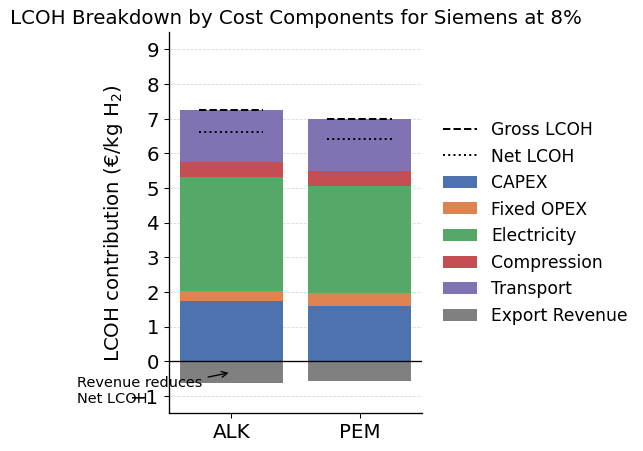

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Style (keep similar look, just cleaner) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15
})

labels = ["ALK", "PEM"]
x = np.arange(len(labels))

def lcoh_component(results, tech, key):
    return results[tech]["costs"][key] / results[tech]["annual_h2_kg"]

capex       = np.array([lcoh_component(results, "ALK", "capex"),
                        lcoh_component(results, "PEM", "capex")])

opex        = np.array([lcoh_component(results, "ALK", "opex"),
                        lcoh_component(results, "PEM", "opex")])

electricity = np.array([lcoh_component(results, "ALK", "electricity"),
                        lcoh_component(results, "PEM", "electricity")])

compression = np.array([lcoh_component(results, "ALK", "compression"),
                        lcoh_component(results, "PEM", "compression")])

transport   = np.array([lcoh_component(results, "ALK", "transport"),
                        lcoh_component(results, "PEM", "transport")])

export      = np.array([-lcoh_component(results, "ALK", "export"),
                        -lcoh_component(results, "PEM", "export")])

gross_lcoh = capex + opex + electricity + compression + transport
net_lcoh   = gross_lcoh + export

# ---- Figure ----
fig, ax = plt.subplots(figsize=(7.5, 5))

bottom = np.zeros(len(x))

# Keep your original colors (just slightly softened)
ax.bar(x, capex, bottom=bottom, color="#4C72B0", label="CAPEX"); bottom += capex
ax.bar(x, opex, bottom=bottom, color="#DD8452", label="Fixed OPEX"); bottom += opex
ax.bar(x, electricity, bottom=bottom, color="#55A868", label="Electricity"); bottom += electricity
ax.bar(x, compression, bottom=bottom, color="#C44E52", label="Compression"); bottom += compression
ax.bar(x, transport, bottom=bottom, color="#8172B3", label="Transport"); bottom += transport

# Export (negative, grey like your figure)
ax.bar(x, export, color="gray", label="Export Revenue")

# Zero line
ax.axhline(0, color="black", linewidth=1)

# Gross & Net lines
for i in range(len(x)):
    ax.hlines(gross_lcoh[i], i-0.25, i+0.25,
              linestyles="--", color="black",
              label="Gross LCOH" if i == 0 else None)
    
    ax.hlines(net_lcoh[i], i-0.25, i+0.25,
              linestyles=":", color="black",
              label="Net LCOH" if i == 0 else None)

# Annotation (bottom-left like your image)
ax.annotate("Revenue reduces\nNet LCOH",
            xy=(0, export[0]/2),
            xytext=(-1.2, -1.2),
            arrowprops=dict(arrowstyle="->", lw=1),
            fontsize=11)

# Labels and title
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=15)
ax.set_ylabel("LCOH contribution (€/kg H$_2$)", fontsize=15)
ax.set_title("LCOH Breakdown by Cost Components for Siemens at 8%", fontsize=15)

# Limits and ticks
ax.set_ylim(-1.5, 9.5)
ax.set_yticks(np.arange(-1, 10, 1))

# Grid (lighter like journal style)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.5)
ax.set_axisbelow(True)

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend on right
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=13)

ax.tick_params(axis="both", labelsize=15)

plt.tight_layout()

# ---- Save (IMPORTANT for journal) ----
plt.savefig("lcoh_breakdown_journal Siemens.png", dpi=600, bbox_inches="tight")
plt.savefig("lcoh_breakdown_journal Siemens.pdf", bbox_inches="tight")  # preferred

plt.show()

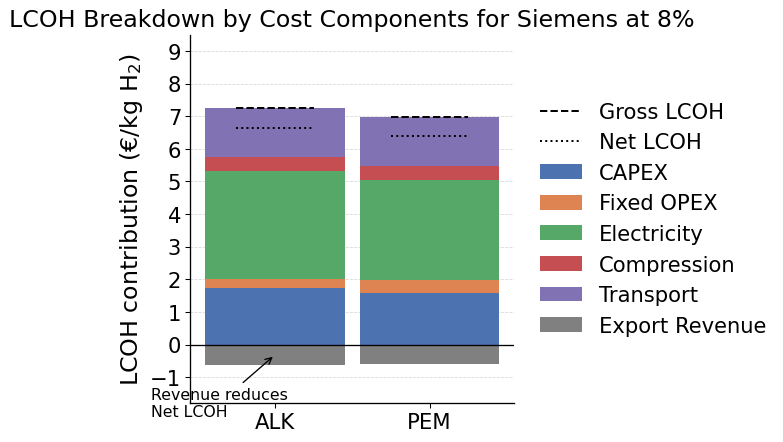

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Style (keep similar look, just cleaner) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "legend.fontsize": 15
})

labels = ["ALK", "PEM"]
x = np.arange(len(labels))

def lcoh_component(results, tech, key):
    return results[tech]["costs"][key] / results[tech]["annual_h2_kg"]

capex       = np.array([lcoh_component(results, "ALK", "capex"),
                        lcoh_component(results, "PEM", "capex")])

opex        = np.array([lcoh_component(results, "ALK", "opex"),
                        lcoh_component(results, "PEM", "opex")])

electricity = np.array([lcoh_component(results, "ALK", "electricity"),
                        lcoh_component(results, "PEM", "electricity")])

compression = np.array([lcoh_component(results, "ALK", "compression"),
                        lcoh_component(results, "PEM", "compression")])

transport   = np.array([lcoh_component(results, "ALK", "transport"),
                        lcoh_component(results, "PEM", "transport")])

export      = np.array([-lcoh_component(results, "ALK", "export"),
                        -lcoh_component(results, "PEM", "export")])

gross_lcoh = capex + opex + electricity + compression + transport
net_lcoh   = gross_lcoh + export

# ---- Figure ----
fig, ax = plt.subplots(figsize=(7.5, 5))

bottom = np.zeros(len(x))


width = 0.9   # increase from default (~0.8 spacing effect)

ax.bar(x, capex, width=width, bottom=bottom, color="#4C72B0", label="CAPEX"); bottom += capex
ax.bar(x, opex, width=width, bottom=bottom, color="#DD8452", label="Fixed OPEX"); bottom += opex
ax.bar(x, electricity, width=width, bottom=bottom, color="#55A868", label="Electricity"); bottom += electricity
ax.bar(x, compression, width=width, bottom=bottom, color="#C44E52", label="Compression"); bottom += compression
ax.bar(x, transport, width=width, bottom=bottom, color="#8172B3", label="Transport"); bottom += transport

# Export
ax.bar(x, export, width=width, color="gray", label="Export Revenue")


# Export (negative, grey like your figure)
#ax.bar(x, export, color="gray", label="Export Revenue")

# Zero line
ax.axhline(0, color="black", linewidth=1)

# Gross & Net lines
for i in range(len(x)):
    ax.hlines(gross_lcoh[i], i-0.25, i+0.25,
              linestyles="--", color="black",
              label="Gross LCOH" if i == 0 else None)
    
    ax.hlines(net_lcoh[i], i-0.25, i+0.25,
              linestyles=":", color="black",
              label="Net LCOH" if i == 0 else None)

# Annotation (bottom-left like your image)
ax.annotate("Revenue reduces\nNet LCOH",
            xy=(0, export[0]/2),
            xytext=(-0.8, -2.2),
            arrowprops=dict(arrowstyle="->", lw=1),
            fontsize=12)

# Labels and title
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=18)
ax.set_ylabel("LCOH contribution (€/kg H$_2$)", fontsize=18)
ax.set_title("LCOH Breakdown by Cost Components for Siemens at 8%", fontsize=18)

# Limits and ticks
ax.set_ylim(-1.8, 9.5)
ax.set_yticks(np.arange(-1, 10, 1))

# Grid (lighter like journal style)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.5)
ax.set_axisbelow(True)

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend on right
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=16)

ax.tick_params(axis="both", labelsize=16)

plt.tight_layout()


plt.show()

-----------------------------------------------

In [10]:
assert "results" in globals(), "Run the model cell first — 'results' not found"


results = {}
for tech, params in TECHS.items():
    results[tech] = run_model(tech, params)


-----------------------------------------------

In [11]:
print(results.keys())
print(results["ALK"].keys())
print(results["ALK"]["monthly"].columns)


dict_keys(['ALK', 'PEM'])
dict_keys(['hourly', 'monthly', 'annual_h2_kg', 'costs'])
Index(['ely_power_eff', 'grid_import_eff', 'surplus_export', 'H2_kg'], dtype='object')


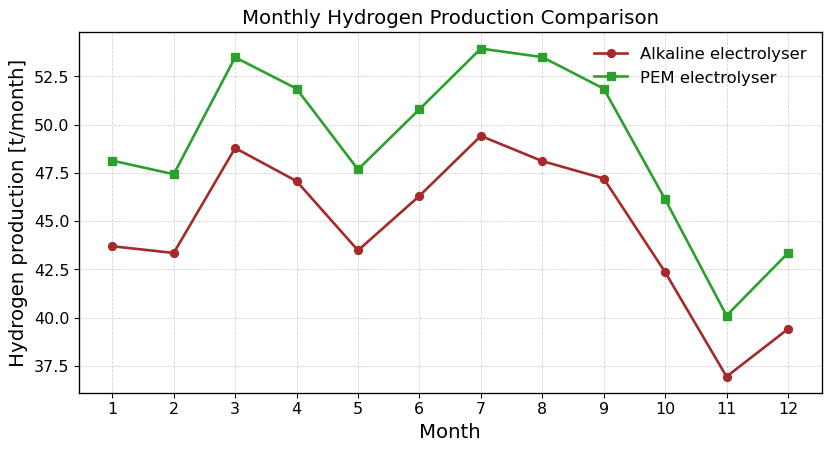

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Style (keep similar look, just cleaner) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 12.5
})

months = np.arange(1, 13)

alk_h2 = results["ALK"]["monthly"]["H2_kg"].values / 1000
pem_h2 = results["PEM"]["monthly"]["H2_kg"].values / 1000

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    months, alk_h2,
    marker="o", linewidth=2,
    label="Alkaline electrolyser",
    color="brown"
)

ax.plot(
    months, pem_h2,
    marker="s", linewidth=2,
    label="PEM electrolyser",
    color="#2ca02c"
)

ax.set_xlabel("Month", fontsize=15)
ax.set_ylabel("Hydrogen production [t/month]", fontsize=15)
ax.set_title("Monthly Hydrogen Production Comparison" , fontsize=15)

ax.set_xticks(months)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=False, loc="upper right", fontsize=12.5)

plt.tight_layout()
plt.show()


-----------------------------------

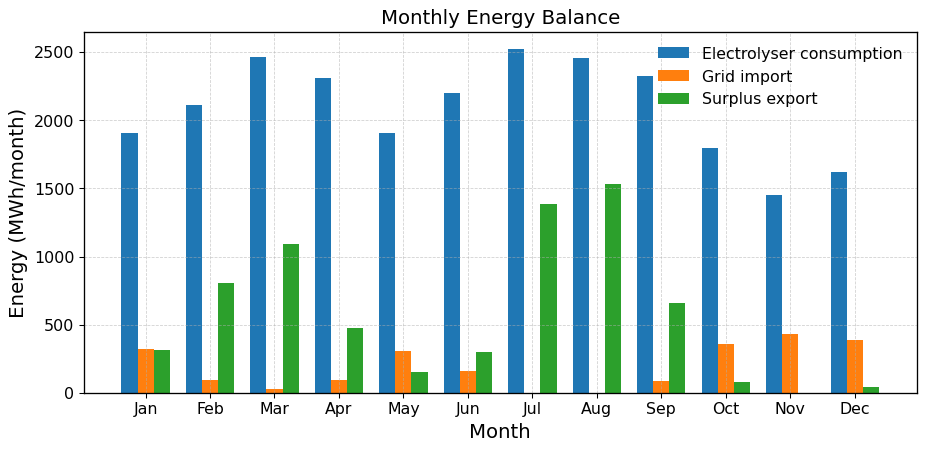

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Style (keep similar look, just cleaner) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 12.5
})

# ==============================
# SELECT MONTHLY DATA ONLY
# ==============================
monthly = comparison.iloc[:12]   # exclude "Total" row

months = np.arange(1, 13)
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    months - width,
    monthly["ELY_energy_MWh"],
    width=width,
    label="Electrolyser consumption",
)

ax.bar(
    months,
    monthly["Grid_import_MWh"],
    width=width,
    label="Grid import",
)

ax.bar(
    months + width,
    monthly["Surplus_export_MWh"],
    width=width,
    label="Surplus export",
)

# ==============================
# LABELS & FORMATTING
# ==============================
ax.set_xlabel("Month", fontsize=15)
ax.set_ylabel("Energy (MWh/month)", fontsize=15)
ax.set_title("Monthly Energy Balance", fontsize=15)

ax.set_xticks(months)
ax.set_xticklabels(
    ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
)

ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=False, fontsize=12)

plt.tight_layout()
plt.show()


-----------------------------------------------------------

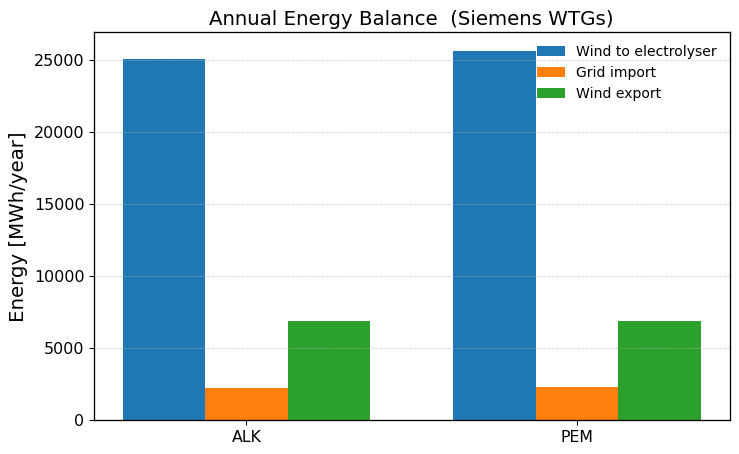

In [14]:
# ---- Style (keep similar look, just cleaner) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 14,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 12.5
})

labels = ["ALK", "PEM"]

ely_energy = [
    results["ALK"]["hourly"]["ely_power_eff"].sum(),
    results["PEM"]["hourly"]["ely_power_eff"].sum()
]

grid_energy = [
    results["ALK"]["hourly"]["grid_import_eff"].sum(),
    results["PEM"]["hourly"]["grid_import_eff"].sum()
]

export_energy = [
    results["ALK"]["hourly"]["surplus_export"].sum(),
    results["PEM"]["hourly"]["surplus_export"].sum()
]

x = np.arange(len(labels))
w = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - w, ely_energy, w, label="Wind to electrolyser")
ax.bar(x, grid_energy, w, label="Grid import")
ax.bar(x + w, export_energy, w, label="Wind export")

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("Energy [MWh/year]", fontsize=15)
ax.set_title("Annual Energy Balance  (Siemens WTGs)", fontsize= 15)

ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.legend(frameon=False, fontsize=10.6)

plt.tight_layout()
plt.show()


---------------------------------------------------

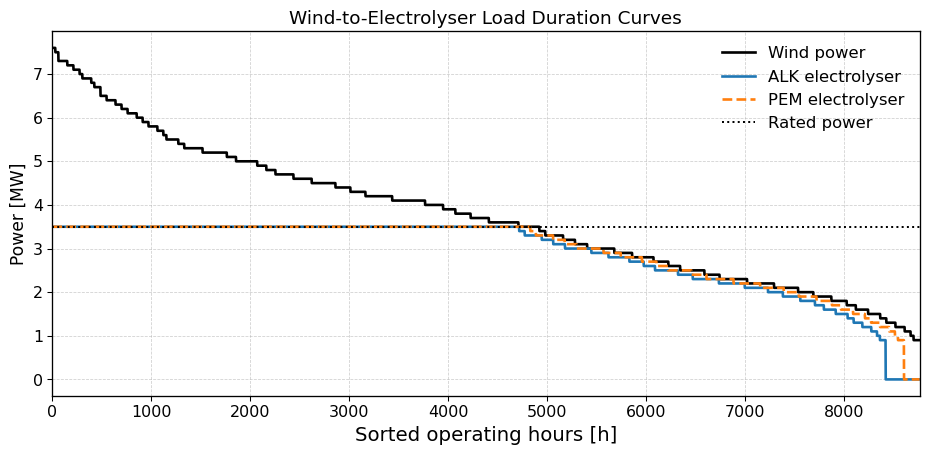

In [15]:
hours = np.arange(1, 8761)

wind_sorted = np.sort(results["ALK"]["hourly"]["wind_p"].values)[::-1]
alk_sorted  = np.sort(results["ALK"]["hourly"]["ely_power_eff"].values)[::-1]
pem_sorted  = np.sort(results["PEM"]["hourly"]["ely_power_eff"].values)[::-1]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(hours, wind_sorted, color="black", linewidth=2, label="Wind power")
ax.plot(hours, alk_sorted, linewidth=2, label="ALK electrolyser")
ax.plot(hours, pem_sorted, linewidth=2, linestyle="--", label="PEM electrolyser")

ax.axhline(ELY_SIZE_MW, color="black", linestyle=":", label="Rated power")

ax.set_xlim(0, 8760)
ax.set_xlabel("Sorted operating hours [h]")
ax.set_ylabel("Power [MW]", fontsize=13)
ax.set_title("Wind-to-Electrolyser Load Duration Curves", fontsize=14)

ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


----------------------------------------------------------------------

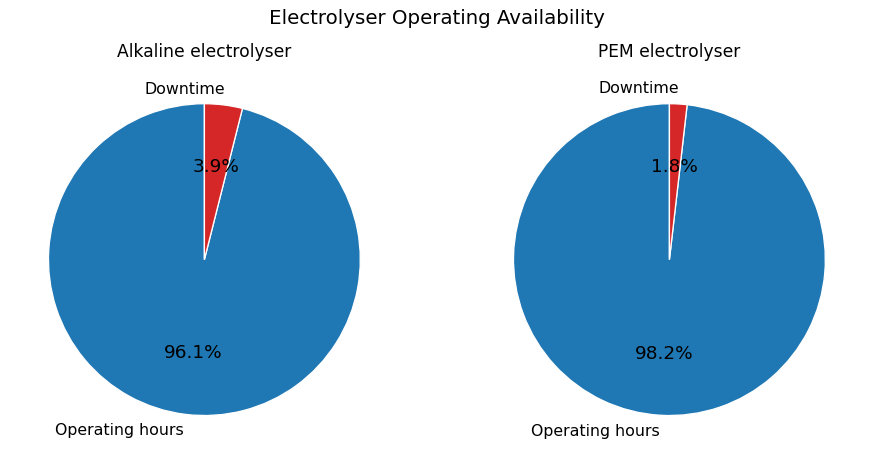

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

labels = ["Operating hours", "Downtime"]
colors = ["#1f77b4", "#d62728"]
fontsize=13

# ALK
axes[0].pie(
    [8416, 344],
    labels=labels,
    autopct="%.1f%%",
    startangle=90,
    colors=colors,
    radius=1.0,                     # <-- bigger pie
    wedgeprops={"edgecolor": "white"},
    center=(-0.8, 9)   
)
axes[0].set_title("Alkaline electrolyser", fontsize=13, loc="center")

# PEM
axes[1].pie(
    [8601, 159],
    labels=labels,
    autopct="%.1f%%",
    startangle=90,
    colors=colors,
    radius=1.0,                     # <-- bigger pie
    wedgeprops={"edgecolor": "white"},
    center=(-0.8, 0)   
)
axes[1].set_title("PEM electrolyser", fontsize=13, loc="center")

plt.suptitle("Electrolyser Operating Availability", fontsize=15)
plt.tight_layout()
plt.show()

--------------------------------------------------

In [17]:
assert "results" in globals(), "Run the model cell first — 'results' not found"

print(results.keys())
print(results["ALK"].keys())
print(results["ALK"]["monthly"].columns)


dict_keys(['ALK', 'PEM'])
dict_keys(['hourly', 'monthly', 'annual_h2_kg', 'costs'])
Index(['ely_power_eff', 'grid_import_eff', 'surplus_export', 'H2_kg'], dtype='object')


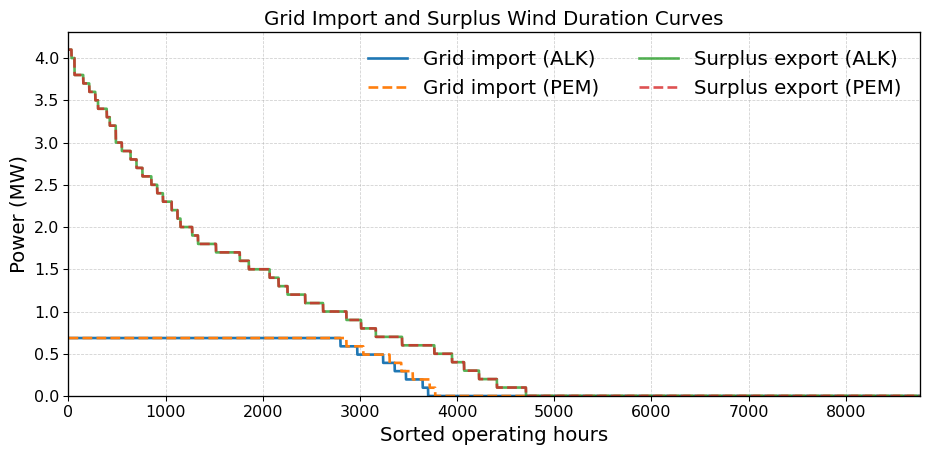

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Extract hourly data
alk_hourly = results["ALK"]["hourly"]
pem_hourly = results["PEM"]["hourly"]

# Sort descending (duration curves)
alk_grid_sorted = np.sort(alk_hourly["grid_import_eff"].values)[::-1]
alk_surplus_sorted = np.sort(alk_hourly["surplus_export"].values)[::-1]

pem_grid_sorted = np.sort(pem_hourly["grid_import_eff"].values)[::-1]
pem_surplus_sorted = np.sort(pem_hourly["surplus_export"].values)[::-1]

hours = np.arange(1, 8761)

fig, ax = plt.subplots(figsize=(10, 5))

# ---- Grid import ----
ax.plot(
    hours,
    alk_grid_sorted,
    label="Grid import (ALK)",
    linewidth=2
)

ax.plot(
    hours,
    pem_grid_sorted,
    label="Grid import (PEM)",
    linewidth=2,
    linestyle="--"
)

# ---- Surplus export ----
ax.plot(
    hours,
    alk_surplus_sorted,
    label="Surplus export (ALK)",
    linewidth=2,
    alpha=0.8
)

ax.plot(
    hours,
    pem_surplus_sorted,
    label="Surplus export (PEM)",
    linewidth=2,
    linestyle="--",
    alpha=0.8
)

# ---- Formatting ----
ax.set_xlabel("Sorted operating hours", fontsize=15)
ax.set_ylabel("Power (MW)", fontsize=15)
ax.set_title("Grid Import and Surplus Wind Duration Curves", fontsize=15)

ax.set_xlim(0, 8760)
ax.set_ylim(
    0,
    max(
        alk_grid_sorted.max(),
        pem_grid_sorted.max(),
        alk_surplus_sorted.max(),
        pem_surplus_sorted.max()
    ) * 1.05
)

ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=False, ncol=2, fontsize=15)

plt.tight_layout()
plt.show()


--------------------------------

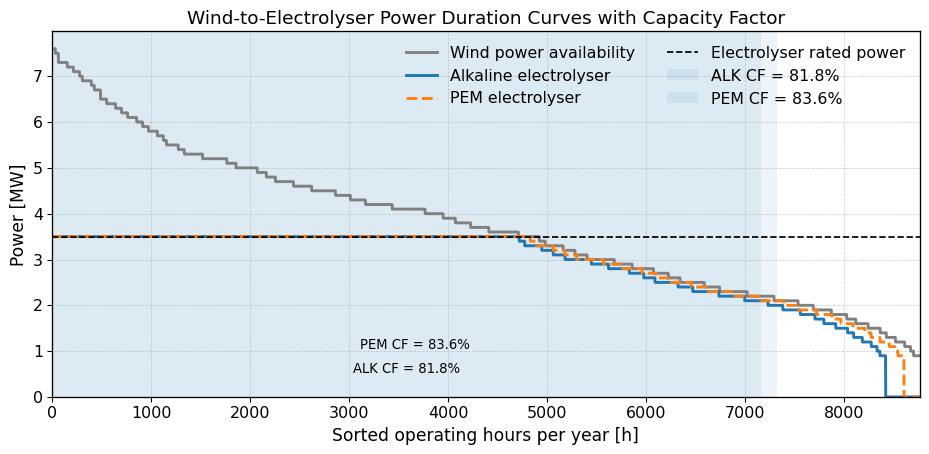

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================
# DATA (FIXED ACCESS PATHS)
# ==============================
alk_hourly = results["ALK"]["hourly"]
pem_hourly = results["PEM"]["hourly"]

alk_sorted = np.sort(alk_hourly["ely_power_eff"].values)[::-1]
pem_sorted = np.sort(pem_hourly["ely_power_eff"].values)[::-1]

# Wind is identical for both → take from ALK
wind_sorted = np.sort(alk_hourly["wind_p"].values)[::-1]

hours = np.arange(1, 8761)

# ==============================
# Capacity factors (derived, robust)
# ==============================
cf_alk = alk_sorted.sum() / (ELY_SIZE_MW * 8760)
cf_pem = pem_sorted.sum() / (ELY_SIZE_MW * 8760)

cf_alk_hours = int(cf_alk * 8760)
cf_pem_hours = int(cf_pem * 8760)

# ==============================
# FIGURE
# ==============================
fig, ax = plt.subplots(figsize=(10, 5))

# ---- Wind duration curve
ax.plot(
    hours,
    wind_sorted,
    color="gray",
    linewidth=2.2,
    label="Wind power availability"
)

# ---- Electrolyser duration curves
ax.plot(
    hours,
    alk_sorted,
    linewidth=2.2,
    label="Alkaline electrolyser"
)

ax.plot(
    hours,
    pem_sorted,
    linestyle="--",
    linewidth=2.2,
    label="PEM electrolyser"
)

# ---- Rated power
ax.axhline(
    y=ELY_SIZE_MW,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Electrolyser rated power"
)

# ==============================
# CAPACITY FACTOR SHADING
# ==============================
ax.axvspan(
    0,
    cf_alk_hours,
    alpha=0.08,
    label=f"ALK CF = {cf_alk:.1%}"
)

ax.axvspan(
    0,
    cf_pem_hours,
    alpha=0.08,
    label=f"PEM CF = {cf_pem:.1%}"
)

# ---- Text annotations
ax.text(
    cf_alk_hours * 0.5,
    ELY_SIZE_MW * 0.15,
    f"ALK CF = {cf_alk:.1%}",
    ha="center",
    fontsize=10
)

ax.text(
    cf_pem_hours * 0.5,
    ELY_SIZE_MW * 0.30,
    f"PEM CF = {cf_pem:.1%}",
    ha="center",
    fontsize=10
)

# ==============================
# AXES & STYLING
# ==============================
ax.set_xlim(0, 8760)
ax.set_ylim(0, max(wind_sorted.max(), ELY_SIZE_MW) * 1.05)

ax.set_xlabel("Sorted operating hours per year [h]", fontsize=13)
ax.set_ylabel("Power [MW]", fontsize=13)
ax.set_title(
    "Wind-to-Electrolyser Power Duration Curves with Capacity Factor",
    fontsize=14
)

ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=False, fontsize=12, ncol=2)

plt.tight_layout()
plt.show()


------------------------------------

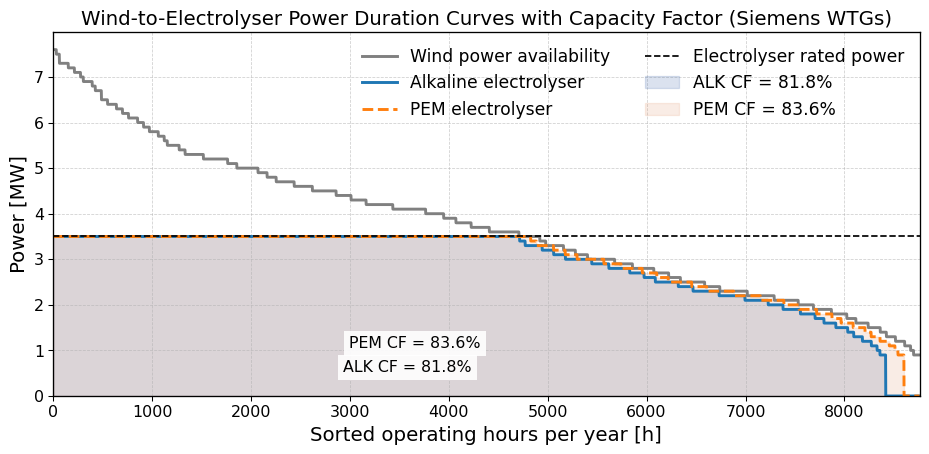

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================
# DATA (FIXED ACCESS PATHS)
# ==============================
alk_hourly = results["ALK"]["hourly"]
pem_hourly = results["PEM"]["hourly"]

alk_sorted = np.sort(alk_hourly["ely_power_eff"].values)[::-1]
pem_sorted = np.sort(pem_hourly["ely_power_eff"].values)[::-1]

# Wind is identical for both → take from ALK
wind_sorted = np.sort(alk_hourly["wind_p"].values)[::-1]

hours = np.arange(1, 8761)

# ==============================
# Capacity factors (derived, robust)
# ==============================
cf_alk = alk_sorted.sum() / (ELY_SIZE_MW * 8760)
cf_pem = pem_sorted.sum() / (ELY_SIZE_MW * 8760)

cf_alk_hours = int(cf_alk * 8760)
cf_pem_hours = int(cf_pem * 8760)

# ==============================
# FIGURE
# ==============================
fig, ax = plt.subplots(figsize=(10, 5))

# ---- Wind duration curve
ax.plot(
    hours,
    wind_sorted,
    color="gray",
    linewidth=2.2,
    label="Wind power availability"
)

# ---- Electrolyser duration curves
ax.plot(
    hours,
    alk_sorted,
    linewidth=2.2,
    label="Alkaline electrolyser"
)

ax.plot(
    hours,
    pem_sorted,
    linestyle="--",
    linewidth=2.2,
    label="PEM electrolyser"
)

# ---- Rated power
ax.axhline(
    y=ELY_SIZE_MW,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Electrolyser rated power"
)

# ==============================
# CAPACITY FACTOR SHADING
# ==============================
# ax.axvspan(
#      0,
#      cf_alk_hours,
#      color="#4C72B0",
#      alpha=0.08,
#      label=f"ALK CF = {cf_alk:.1%}"
#  )

# ax.axvspan(
#      0,
#      cf_pem_hours,
#      color="#DD8452",
#      alpha=0.08,
#      label=f"PEM CF = {cf_pem:.1%}"
#  )


# 2. CAPACITY FACTOR SHADING (Perfect Fit)
# We shade the area between 0 and the actual electrolyzer curve
ax.fill_between(
    hours, 0, alk_sorted, 
    color="#4C72B0", alpha=0.2, 
    label=f"ALK CF = {cf_alk:.1%}"
)

ax.fill_between(
    hours, 0, pem_sorted, 
    color="#DD8452", alpha=0.15, 
    label=f"PEM CF = {cf_pem:.1%}"
)
# --- ALK Shading ---
# ax.fill_between(
#     x, 
#     0, 
#     wind_power, 
#     where=(x <= cf_alk_hours), 
#     color="#4C72B0",       # Steel Blue
#     alpha=0.2,             # Slightly higher for clarity
#     label=f"ALK (CF: {cf_alk:.1%})"
# )

# # --- PEM Shading ---
# ax.fill_between(
#     x, 
#     0, 
#     wind_power, 
#     where=(x <= cf_pem_hours), 
#     color="#DD8452",       # Burnt Orange (Distinct from ALK)
#     alpha=0.15, 
#     label=f"PEM (CF: {cf_pem:.1%})"
# )


# # ALK shading
# ax.fill_between(
#     x,
#     0,
#     upper_alk,
#     where=(x <= cf_alk_hours),
#     interpolate=True,
#     color="#4C72B0",
#     alpha=0.10,
#     label=f"ALK CF = {cf_alk:.1%}"
# )

# # PEM shading
# ax.fill_between(
#     x,
#     0,
#     upper_pem,
#     where=(x <= cf_pem_hours),
#     interpolate=True,
#     color="#DD8452",
#     alpha=0.10,
#     label=f"PEM CF = {cf_pem:.1%}"
# )

# ---- Text annotations
ax.text(
    cf_alk_hours * 0.5,
    ELY_SIZE_MW * 0.15,
    f"ALK CF = {cf_alk:.1%}",
    ha="center",
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.9)
)

ax.text(
    cf_pem_hours * 0.5,
    ELY_SIZE_MW * 0.30,
    f"PEM CF = {cf_pem:.1%}",
    ha="center",
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.9)
)

# ==============================
# AXES & STYLING
# ==============================
ax.set_xlim(0, 8760)
ax.set_ylim(0, max(wind_sorted.max(), ELY_SIZE_MW) * 1.05)

ax.set_xlabel("Sorted operating hours per year [h]", fontsize=15)
ax.set_ylabel("Power [MW]", fontsize=15)
ax.set_title(
    "Wind-to-Electrolyser Power Duration Curves with Capacity Factor (Siemens WTGs)",
    fontsize=15
)

ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=False, fontsize=13, ncol=2)
ax.legend(loc="upper right", bbox_to_anchor=(1, 1), frameon=False, fontsize=13, ncol=2)

plt.tight_layout()
plt.show()


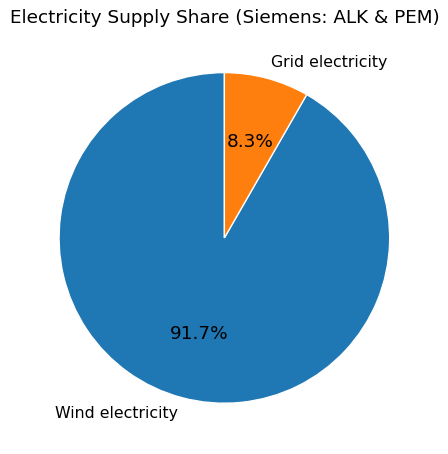

In [21]:
import matplotlib.pyplot as plt

# ---- Style settings (journal-ready) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 13
})

fig, ax = plt.subplots(figsize=(5, 5))

labels = ["Wind electricity", "Grid electricity"]
colors = ["#1f77b4", "#ff7f0e"]   # #2ca02c
fontsize= 15

ax.pie(
    [0.917, 0.083],
    labels=labels,
    autopct="%.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white"},
    radius=1.0
)

ax.set_title("Electricity Supply Share (Siemens: ALK & PEM)", fontsize=14)

ax.set(aspect="equal")
plt.tight_layout()
plt.show()


-----------------------------------------------------------------

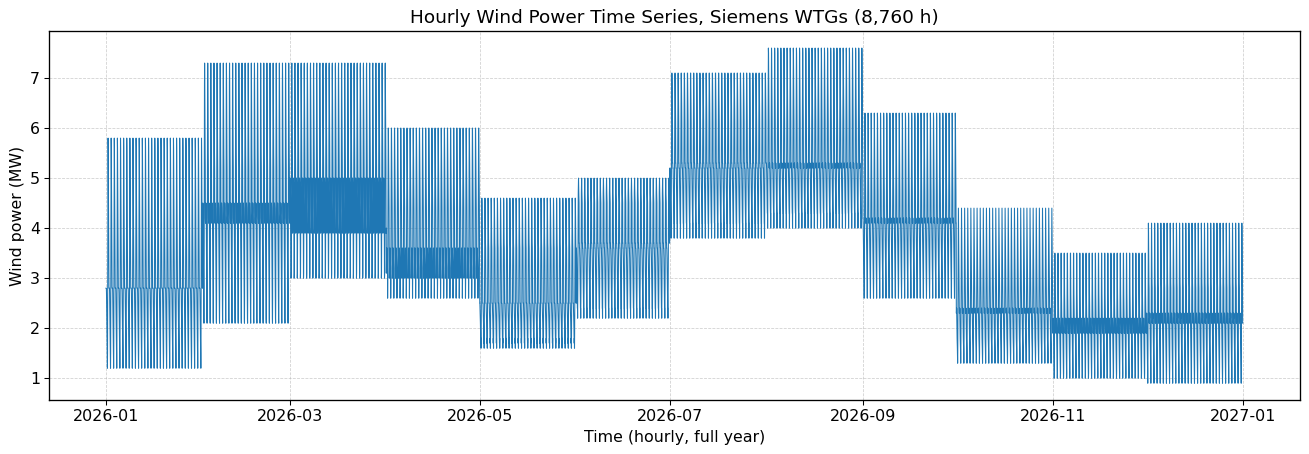

In [22]:
import matplotlib.pyplot as plt

# Extract hourly dataframe (same for ALK & PEM)
df = results["ALK"]["hourly"]

plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df["wind_p"],
    linewidth=0.8,
    color="#1f77b4"               #"gray"
)

plt.xlabel("Time (hourly, full year)", fontsize=12)
plt.ylabel("Wind power (MW)", fontsize=12)
plt.title("Hourly Wind Power Time Series, Siemens WTGs (8,760 h)", fontsize=14)

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


-----------------------------------------------------

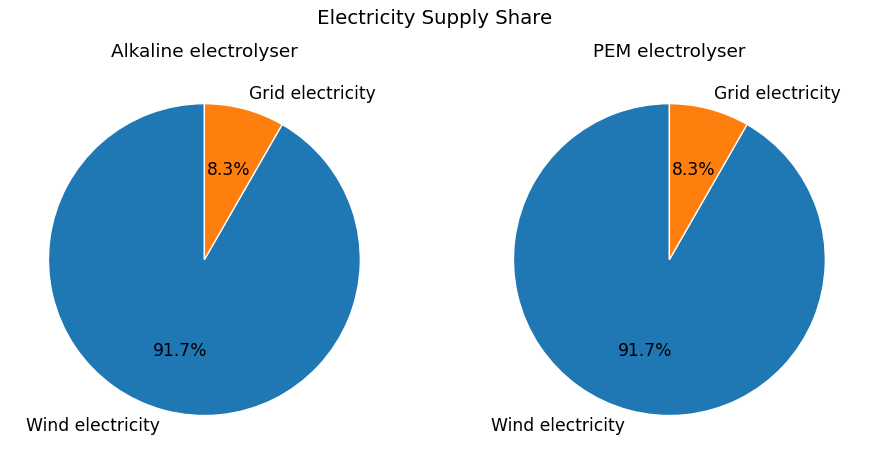

In [23]:
import matplotlib.pyplot as plt

# ==============================
# EXTRACT ELECTRICITY SHARES
# ==============================
def electricity_share(tech):
    df = results[tech]["hourly"]
    wind_mwh = df["ely_power_eff"].sum()
    grid_mwh = df["grid_import_eff"].sum()
    total = wind_mwh + grid_mwh
    return wind_mwh / total, grid_mwh / total


alk_wind, alk_grid = electricity_share("ALK")
pem_wind, pem_grid = electricity_share("PEM")

# ==============================
# PLOT
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

labels = ["Wind electricity", "Grid electricity"]
colors = ["#1f77b4", "#ff7f0e"]
fontsize = 13

# ---- ALK ----
axes[0].pie(
    [alk_wind, alk_grid],
    labels=labels,
    autopct="%.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": fontsize}
)
axes[0].set_title("Alkaline electrolyser", fontsize=14)
axes[0].set_aspect("equal")

# ---- PEM ----
axes[1].pie(
    [pem_wind, pem_grid],
    labels=labels,
    autopct="%.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": fontsize}
)
axes[1].set_title("PEM electrolyser", fontsize=14)
axes[1].set_aspect("equal")

plt.suptitle("Electricity Supply Share", fontsize=15)
plt.tight_layout()
plt.show()


#### ALK and PEM have the similar electricity supply share (%) while using different absolute amounts of wind electricity (MWh)

| Electrolyser | Wind used (MWh) | Grid used (MWh) | Total (MWh) |
|--------------|------------------|------------------|--------------|
| ALK          | 31,975           | ~2,980           | ~34,955      |
| PEM          | 32,681           | ~3,050           | ~35,731      |


**ALK wind share**

Wind share = 31,975 / (31,975 + 2,980) ≈ 0.915 ≈ **91.5%**

**PEM wind share**

Wind share = 32,681 / (32,681 + 3,050) ≈ 0.915 ≈ **91.5%**


--------------------------------------------------------------------------------------------------------------------------------------

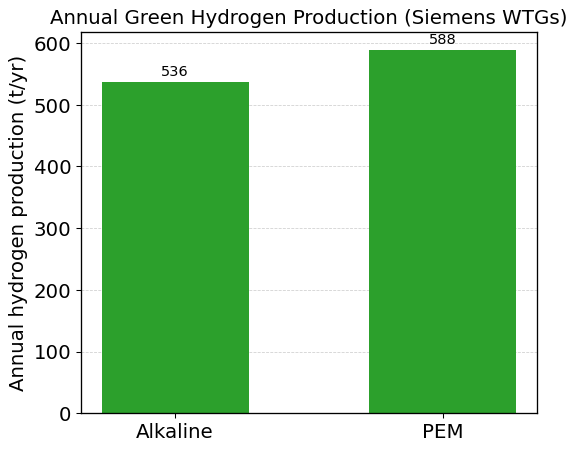

In [28]:
import matplotlib.pyplot as plt

# ---- Style settings (journal-ready) ----
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 9
})

fig, ax = plt.subplots(figsize=(6, 5))

labels = ["Alkaline", "PEM"]

values = [
    results["ALK"]["annual_h2_kg"] / 1000,  # tonnes/year
    results["PEM"]["annual_h2_kg"] / 1000
]

bars = ax.bar(
    labels,
    values,
    color=["#2ca02c","#2ca02c"],
    width=0.55
)

# Labels & title
ax.set_ylabel("Annual hydrogen production (t/yr)", fontsize=15)
ax.set_title("Annual Green Hydrogen Production (Siemens WTGs)", fontsize=15)

# Grid
ax.grid(True, axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)

# Value labels
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height * 1.01,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.tick_params(axis="both", labelsize=15)

plt.savefig("Annual Green Hydrogen Production (8Siemens WTGs).png", dpi=600, bbox_inches="tight")


plt.tight_layout()
plt.show()


-----------------------------------------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------End------------------------------------------------------------------------------------